# 1. Exploring Moscow road-crash data

**Data:** open data from [dtp-stat.ru](https://dtp-stat.ru/opendata/), built from traffic police (GIBDD) records.
Every record is a crash in which at least one person was injured or killed.

**Goal of this notebook:** understand what the columns mean and how clean they are before building any model,
and decide what to predict.

In [1]:
import json
import pandas as pd

In [2]:
path = "../data/moskva.geojson/moskva.geojson"

with open(path, encoding="utf-8") as f:
    data = json.load(f)

## What does one crash look like?
The file is GeoJSON: a list of `features`, one per crash. Each has `geometry` (coordinates) and `properties` (everything else).
Some properties are lists, because a crash can involve several cars and people or several weather conditions at once.

In [3]:
first = data["features"][0]
print(first.keys())
# Show only the structure (field -> type), not the values:
# a single record contains an exact address and details about real people.
{key: type(value).__name__ for key, value in first["properties"].items()}

dict_keys(['type', 'geometry', 'properties'])


{'id': 'int', 'tags': 'list', 'light': 'str', 'point': 'dict', 'nearby': 'list', 'region': 'str', 'scheme': 'str', 'address': 'str', 'weather': 'list', 'category': 'str', 'datetime': 'str', 'severity': 'str', 'vehicles': 'list', 'dead_count': 'int', 'gibdd_number': 'str', 'participants': 'list', 'injured_count': 'int', 'parent_region': 'str', 'road_conditions': 'list', 'participants_count': 'int', 'participant_categories': 'list'}

## Turn it into a table
`json_normalize` makes one row per crash and one column per field. List fields stay as lists inside a cell.

In [4]:
rows = [feat["properties"] for feat in data["features"]]
df = pd.json_normalize(rows)

In [5]:
print(df.shape)
print(df.columns.tolist())
# address, coordinates and the people lists are left out of the preview on purpose
df.drop(columns=["address", "point.lat", "point.long", "vehicles", "participants"]).head()

(94786, 22)
['id', 'tags', 'light', 'nearby', 'region', 'scheme', 'address', 'weather', 'category', 'datetime', 'severity', 'vehicles', 'dead_count', 'gibdd_number', 'participants', 'injured_count', 'parent_region', 'road_conditions', 'participants_count', 'participant_categories', 'point.lat', 'point.long']


,id,tags,light,nearby,region,scheme,weather,category,datetime,severity,dead_count,gibdd_number,injured_count,parent_region,road_conditions,participants_count,participant_categories
0,6,[Дорожно-транспортные происшествия],"В темное время суток, освещение включено",[Отсутствие в непосредственной близости объект...,Котловка,610,[Пасмурно],Наезд на препятствие,2015-01-01 00:23:00,С погибшими,1,157054063,1,Москва,"[Отсутствие, плохая различимость вертикальной ...",2,[Все участники]
1,22,[Дорожно-транспортные происшествия],"В темное время суток, освещение включено","[Жилые дома индивидуальной застройки, Нерегули...",Марьино,740,[Пасмурно],Наезд на пешехода,2015-01-01 01:00:00,Тяжёлый,0,157125004,1,Москва,[Не установлены],2,"[Все участники, Пешеходы]"
2,44,[Дорожно-транспортные происшествия],"В темное время суток, освещение включено","[Выезд с прилегающей территории, Остановка общ...",Солнцево,210,[Пасмурно],Столкновение,2015-01-01 01:39:00,Тяжёлый,0,157067635,1,Москва,[Недостатки зимнего содержания],3,[Все участники]
3,77,[Дорожно-транспортные происшествия],"В темное время суток, освещение включено",[Отсутствие в непосредственной близости объект...,Бескудниковский,590,[Пасмурно],Наезд на препятствие,2015-01-01 03:00:00,Тяжёлый,0,161850074,1,Москва,[Не установлены],1,[Все участники]
4,91,[Дорожно-транспортные происшествия],"В темное время суток, освещение включено","[Объект (здание, сооружение) религиозного куль...",Рязанский,060,[Пасмурно],Столкновение,2015-01-01 03:35:00,Легкий,0,159327097,1,Москва,[Неудовлетворительное состояние разделительной...,3,[Все участники]


## How severe are crashes?
Only ~4.4% of crashes are fatal. That is the class I want to predict, and it is rare —
a model that always says "not fatal" would already be 95.6% "accurate", so accuracy is useless here.

In [6]:
print(df["severity"].value_counts())
print(df["severity"].value_counts(normalize=True))

severity
Тяжёлый                          53905
Легкий                           36670
С погибшими                       4208
Без пострадавших (нет данных)        3
Name: count, dtype: int64
severity
Тяжёлый                          0.568702
Легкий                           0.386871
С погибшими                      0.044395
Без пострадавших (нет данных)    0.000032
Name: proportion, dtype: float64


## Which years are covered?
2015–2025 are complete; 2026 only has January–February. This decides the train/validation/test split later.

In [7]:
df["datetime"] = pd.to_datetime(df["datetime"])
df["datetime"].dt.year.value_counts().sort_index()

datetime
2015    10299
2016     8308
2017     8256
2018     9073
2019     9211
2020     7913
2021     8438
2022     7641
2023     8042
2024     8859
2025     8354
2026      392
Name: count, dtype: int64

## What values do the list columns contain? How much is missing?
Some weather values (fog, blizzard, hurricane wind) appear only a few dozen times — too rare to learn anything from.

In [8]:
df["weather"].explode().value_counts()

weather
Пасмурно                 47120
Ясно                     42172
Дождь                     4098
Снегопад                  1948
Температура выше +30С       38
Туман                       35
Метель                      18
Ураганный ветер              1
Name: count, dtype: int64

In [9]:
df.isna().sum()

id                           0
tags                         0
light                        0
nearby                       0
region                       0
scheme                       0
address                   8880
weather                      0
category                     0
datetime                     0
severity                     0
vehicles                     0
dead_count                   0
gibdd_number                 0
participants                 0
injured_count                0
parent_region             1429
road_conditions              0
participants_count           0
participant_categories       0
point.lat                   37
point.long                  37
dtype: int64

## Target: was the crash fatal?
`fatal = 1` if at least one person died. I use death rather than "severe injury" because death is unambiguous,
while the severe/light split depends on how injuries are classified.

In [10]:
df = df[df["severity"] != "Без пострадавших (нет данных)"].copy()
df["fatal"] = (df["severity"] == "С погибшими").astype(int)
df["fatal"].mean()

np.float64(0.04439614698838399)

## First look at what is linked to fatal crashes
`groupby(...)["fatal"].mean()` gives the share of fatal crashes in each group. Always check the count next to a rate:
a high rate based on a few dozen crashes means little.

In [11]:
df["hour"] = df["datetime"].dt.hour
df.groupby("hour")["fatal"].mean()

hour
0     0.100182
1     0.094855
2     0.113914
3     0.114738
4     0.105092
5     0.110607
6     0.083614
7     0.045063
8     0.024916
9     0.030884
10    0.030540
11    0.037368
12    0.034106
13    0.027772
14    0.031542
15    0.027809
16    0.029670
17    0.034414
18    0.035597
19    0.042110
20    0.043235
21    0.050434
22    0.063578
23    0.062257
Name: fatal, dtype: float64

In [12]:
display(df.groupby("light")["fatal"].agg(["mean", "count"]))
display(df.groupby("category")["fatal"].agg(["mean", "count"]).sort_values("mean", ascending=False))

,mean,count
light,,
"В темное время суток, освещение включено",0.061274,35366
"В темное время суток, освещение не включено",0.158192,177
"В темное время суток, освещение отсутствует",0.239669,484
Не установлено,0.000000,1
Светлое время суток,0.032082,57321
Сумерки,0.040446,1434


,mean,count
category,,
"Наезд на лицо, не являющееся участником дорожного движения, осуществляющее производство работ",0.276316,76
"Наезд на лицо, не являющееся участником дорожного движения, осуществляющее какую-либо другую деятельность",0.222222,18
Съезд с дороги,0.118182,110
"Наезд на лицо, не являющееся участником дорожного движения, осуществляющее несение службы",0.097561,41
Наезд на препятствие,0.097031,5019
Наезд на стоящее ТС,0.087912,4095
Наезд на животное,0.083333,12
Иной вид ДТП,0.075000,80
Наезд на пешехода,0.063461,32792


## Two plots for the README
Simple rates, before any model. These do not control for other factors (for example, unlit roads may also be faster),
so they show *where to look*, not *what causes* deaths.

In [13]:
import matplotlib.pyplot as plt

BLUE = "#2a78d6"
full_years = df[df["datetime"].dt.year <= 2025]   # 2026 has only Jan-Feb, leave it out

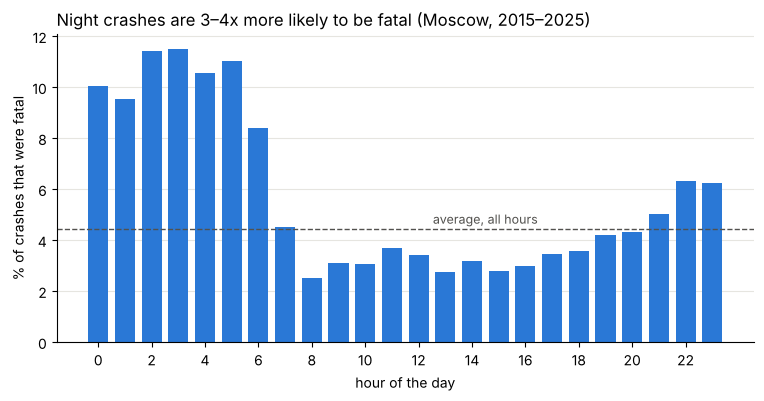

In [14]:
by_hour = full_years.groupby("hour")["fatal"].mean() * 100

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(by_hour.index, by_hour.values, color=BLUE, width=0.75)
ax.axhline(full_years["fatal"].mean() * 100, color="#52514e", linestyle="--", linewidth=1)
ax.text(14.5, full_years["fatal"].mean() * 100 + 0.2, "average, all hours", ha="center", color="#52514e", fontsize=9)
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("hour of the day")
ax.set_ylabel("% of crashes that were fatal")
ax.set_title("Night crashes are 3–4x more likely to be fatal (Moscow, 2015–2025)", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e6e5e0", linewidth=0.8)
ax.set_axisbelow(True)
plt.savefig("../plots/fatal_rate_by_hour.png", dpi=150, bbox_inches="tight")
plt.show()

                             mean  count
light                                   
Daylight                 0.032125  57121
Twilight                 0.040531   1431
Dark, street lights on   0.061400  35179
Dark, street lights off  0.159091    176
Dark, no street lights   0.239669    484


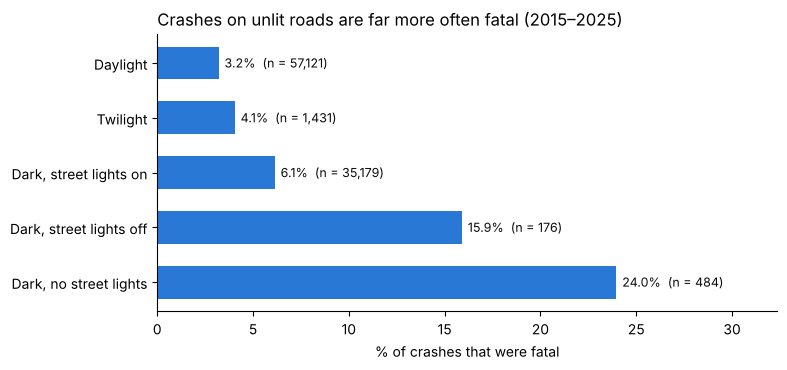

In [15]:
names = {
    "Светлое время суток": "Daylight",
    "Сумерки": "Twilight",
    "В темное время суток, освещение включено": "Dark, street lights on",
    "В темное время суток, освещение не включено": "Dark, street lights off",
    "В темное время суток, освещение отсутствует": "Dark, no street lights",
}
by_light = (full_years[full_years["light"].isin(names)]
            .groupby("light")["fatal"].agg(["mean", "count"])
            .rename(index=names)
            .loc[list(names.values())])
print(by_light)

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(by_light.index, by_light["mean"] * 100, color=BLUE, height=0.6)
for i, (rate, n) in enumerate(zip(by_light["mean"] * 100, by_light["count"])):
    ax.text(rate + 0.3, i, f"{rate:.1f}%  (n = {n:,})", va="center", fontsize=9, color="#0b0b0b")
ax.invert_yaxis()
ax.set_xlabel("% of crashes that were fatal")
ax.set_title("Crashes on unlit roads are far more often fatal (2015–2025)", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.set_xlim(0, by_light["mean"].max() * 100 * 1.35)
plt.savefig("../plots/fatal_rate_by_lighting.png", dpi=150, bbox_inches="tight")
plt.show()